# Step 7.d -- Climate x soil COMBINED suitability, adaptive calendar (+-60 days)

New, parallel notebook (per the user's request, 2026-10-19) -- does **not** touch `7.a)`,
`7.b)` or `7.c)`. Two things change relative to `7.c)`:

1. **Climate x soil combined**, not climate-only. Reuses the exact combination already
   established and validated in
   [5.c)_Apply_ERA5_validation_without_threshold/5.a.bis)_...ipynb](../../5_Suitability_climate_soil_combined_validation/5.c\)_Apply_ERA5_validation_without_threshold/5.a.bis\)_Apply_ERA5_validation_without_threshold.ipynb):
   `combined = climate_proba * soil_index` (soil_index = GAEZ Module IV SSR, continuous
   0-100 rescaled to 0-1; same as GAEZ v5's own Module V combination). Both High and Low
   soil input levels, as in that notebook and in `5.x)`/`6.a)` generally.
2. **No 0.5 binarisation on the suitability map.** The combined score stays continuous
   0-1 and is shown as a green gradient (same convention as `suit_proba` maps elsewhere in
   this project, e.g. `4.f.bis)`'s `cmap='YlGn', vmin=0, vmax=1`) so weakly-suitable pixels
   are visible too, not collapsed to a binary cut.

Climate-side inputs (13 shifts x {ERA5 ref, ISIMIP fut}) are read **unchanged** from
`7.a)`/`7.b)`'s already-computed BIO-variable files -- nothing is recomputed there, this
notebook only adds the soil layer and the combination on top. Same frozen model
(`3.d)_SVM_train_ERA5_MIRCA2000_no_threshold`), still no retraining.

**Per-pixel best shift**: the shift (among the 13 tested, -60..+60 days) that maximises
`combined`, independently for ref and fut. Soil is static (doesn't depend on the calendar),
so `argmax_shift(combined) = argmax_shift(climate_proba)` wherever soil_index > 0 -- soil
only rescales the combined VALUE, not which shift is locally best. Where soil_index == 0
(confirmed: 5 pixels in this soil layer), combined is 0 for every shift and the argmax is a
meaningless tie -- those pixels are masked on the "best shift" map only (the suitability
map legitimately shows 0 there, that's not a gap to hide).

In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import joblib
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')

BASE    = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
DIR_7A  = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.a)_Build_BIOvariables_shifted_calendar_ERA5"
DIR_7B  = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.b)_Build_BIOvariables_futures" / "ISIMIP_2061_2080"
MDL_DIR = BASE / "1_SVM" / "3_SVM_train" / "3.d)_SVM_train_ERA5_MIRCA2000_no_threshold" / "svm_train_outputs_mirca2000_no_threshold"
SOIL_DIR = BASE / "1_SVM" / "2_soil_suitability_gaez" / "soil_suitability_outputs"
OUT_DIR = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.d)_SVM_predict_shifted_calendar_climate_soil_combined" / "out"
OUT_DIR.mkdir(parents=True, exist_ok=True)

CROP_LABEL = 'Maize_rf'
SHIFTS     = [-90, -80, -70, -60, -50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90]
LEVELS     = ['high', 'low']
SOIL_SUFFIX = {'high': '_high', 'low': '_low'}

def shift_tag(d):
    return 'cal' + ('0' if d == 0 else ('P' if d > 0 else 'M') + str(abs(d)))

mdl_path = MDL_DIR / f'svm_model_{CROP_LABEL}.joblib'
print(f'{"OK" if mdl_path.exists() else "MISSING"}: {mdl_path}')
for d in SHIFTS:
    rp = DIR_7A / f'out_{shift_tag(d)}' / f'BIO_{CROP_LABEL}_{shift_tag(d)}.nc'
    fp = DIR_7B / f'out_{shift_tag(d)}' / f'BIO_{CROP_LABEL}_{shift_tag(d)}.nc'
    print(f'  shift {d:+d}d: {"OK" if rp.exists() else "MISSING"} ref | {"OK" if fp.exists() else "MISSING"} fut')
for lv in LEVELS:
    sp = SOIL_DIR / f'soil_suitability_{CROP_LABEL}_1deg_x0grid{SOIL_SUFFIX[lv]}.nc'
    print(f'  soil {lv}: {"OK" if sp.exists() else "MISSING"} {sp.name}')

OK: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\3_SVM_train\3.d)_SVM_train_ERA5_MIRCA2000_no_threshold\svm_train_outputs_mirca2000_no_threshold\svm_model_Maize_rf.joblib
  shift -90d: OK ref | OK fut
  shift -80d: OK ref | OK fut
  shift -70d: OK ref | OK fut
  shift -60d: OK ref | OK fut
  shift -50d: OK ref | OK fut
  shift -40d: OK ref | OK fut
  shift -30d: OK ref | OK fut
  shift -20d: OK ref | OK fut
  shift -10d: OK ref | OK fut
  shift +0d: OK ref | OK fut
  shift +10d: OK ref | OK fut
  shift +20d: OK ref | OK fut
  shift +30d: OK ref | OK fut
  shift +40d: OK ref | OK fut
  shift +50d: OK ref | OK fut
  shift +60d: OK ref | OK fut
  shift +70d: OK ref | OK fut
  shift +80d: OK ref | OK fut
  shift +90d: OK ref | OK fut
  soil high: OK soil_suitability_Maize_rf_1deg_x0grid_high.nc
  soil low: OK soil_suitability_Maize_rf_1deg_x0grid_low.nc


## 1. Load model (frozen) and soil suitability (static, both input levels)

In [2]:
bundle = joblib.load(mdl_path)
print(f'Model   : cost={bundle["best_cost"]}, gamma={bundle["best_gamma"]}')

ds0 = xr.open_dataset(DIR_7A / 'out_cal0' / f'BIO_{CROP_LABEL}_cal0.nc')
lats, lons = ds0.lat.values, ds0.lon.values
nlat, nlon = len(lats), len(lons)
ds0.close()
print(f'Grid    : {nlat} lat x {nlon} lon')

R_earth = 6371.0
lat_area_km2   = (1.0 * np.pi / 180 * R_earth) ** 2 * np.cos(np.radians(lats))
pixel_area_km2 = np.tile(lat_area_km2[:, None], (1, nlon))
pixel_area_Mha = pixel_area_km2 * 100 / 1e6


def predict_suitability(nc_path, bundle):
    """Same pattern as 4.f.bis)/4.1)/7.c) -- frozen scaler+model, no retraining."""
    ds = xr.open_dataset(nc_path)
    X_2d = np.stack([ds[col].values for col in bundle['bio_cols']], axis=-1)
    ds.close()
    X_flat = X_2d.reshape(-1, len(bundle['bio_cols']))
    valid = ~np.any(np.isnan(X_flat), axis=1)
    suit = np.full(nlat * nlon, np.nan)
    if valid.any():
        X_sc = bundle['scaler'].transform(X_flat[valid])
        suit[valid] = bundle['model'].predict_proba(X_sc)[:, 1]
    return suit.reshape(nlat, nlon)


def load_soil_suitability(crop, level):
    """GAEZ Module IV SSR, x.0 grid, 0-100 -> 0-1. Verbatim from 5.c)/5.a.bis)."""
    ds = xr.open_dataset(SOIL_DIR / f'soil_suitability_{crop}_1deg_x0grid{SOIL_SUFFIX[level]}.nc')
    arr = ds[list(ds.data_vars)[0]].values / 100.0
    ds.close()
    return arr


soil_idx = {lv: load_soil_suitability(CROP_LABEL, lv) for lv in LEVELS}
for lv in LEVELS:
    print(f'soil ({lv}): mean={np.nanmean(soil_idx[lv]):.3f}  n==0: {int(np.nansum(soil_idx[lv]==0))}  '
          f'n valid: {int(np.sum(~np.isnan(soil_idx[lv])))}')
print('Functions + soil layers loaded.')

Model   : cost=16.0, gamma=0.1


Grid    : 37 lat x 70 lon


soil (high): mean=0.551  n==0: 5  n valid: 1330
soil (low): mean=0.433  n==0: 5  n valid: 1330
Functions + soil layers loaded.


## 2. Loop over shifts -- climate proba (ref + fut), then combine with soil (both levels)

Soil is static: loaded once above, multiplied in per shift. `combined[level][period][d] =
suit_climate[period][d] * soil_idx[level]`.

In [3]:
suit_ref_by_shift, suit_fut_by_shift = {}, {}
for d in SHIFTS:
    tag = shift_tag(d)
    suit_ref_by_shift[d] = predict_suitability(DIR_7A / f'out_{tag}' / f'BIO_{CROP_LABEL}_{tag}.nc', bundle)
    suit_fut_by_shift[d] = predict_suitability(DIR_7B / f'out_{tag}' / f'BIO_{CROP_LABEL}_{tag}.nc', bundle)
    print(f'shift {d:+3d}d: climate ref/fut computed', flush=True)

combined_ref, combined_fut = {}, {}
for lv in LEVELS:
    combined_ref[lv] = {d: suit_ref_by_shift[d] * soil_idx[lv] for d in SHIFTS}
    combined_fut[lv] = {d: suit_fut_by_shift[d] * soil_idx[lv] for d in SHIFTS}
print('Combined (climate x soil) computed for all shifts, both levels.')

shift -90d: climate ref/fut computed


shift -80d: climate ref/fut computed


shift -70d: climate ref/fut computed


shift -60d: climate ref/fut computed


shift -50d: climate ref/fut computed


...

shift +60d: climate ref/fut computed


shift +70d: climate ref/fut computed


shift +80d: climate ref/fut computed


shift +90d: climate ref/fut computed


Combined (climate x soil) computed for all shifts, both levels.


## 2.5 Empirical calendar envelope -- which shifts are agronomically plausible, per pixel

The +-90d sensitivity test found that "best shift" kept pushing to the edge of the tested
range for cold, high-latitude pixels (Section 8), because the SVM is queried far outside the
calendar configurations it was ever trained on, and nothing in its training data teaches it
to penalise a harvest date that would, in reality, run into autumn frost -- a classic
out-of-distribution extrapolation failure, not evidence the shift test itself is broken (see
the discussion that preceded this section).

**Fix chosen (user's decision, 2026-10-19): an empirical, "ML-native" envelope rather than a
hand-coded physiological guardrail.** A hard rule like "reject if Tmin < 5degC before harvest"
would work for Maize (frost-sensitive throughout) but is the WRONG direction for Wheat-winter
(which *requires* a cold period early in the season for vernalisation) -- any hard
physiological rule has to be reinvented per crop. Instead: only accept a shifted calendar for
a pixel if the resulting sowing date still falls within the range of sowing dates **actually
used by real MIRCA2000 maize cultivation**, among pixels that are *climatically comparable*
to the one being tested. This is the same technique for any crop (only the numeric bound,
read off that crop's own real calendar data, changes), and it never requires knowing *why* a
date is implausible -- only whether it was ever observed somewhere similar.

**Per-latitude-band envelope, not a single Europe-wide one (revised per the user's own
follow-up, 2026-10-20).** A single bound computed over the whole study domain works only
because the domain (Europe) happens to be climatically coherent enough, and because the
model itself is Europe-only anyway -- it stops being valid the moment the domain grows (e.g.
a future global run): a global MIRCA2000 scan would mix in tropical/equatorial maize
calendars sown nearly year-round, which says nothing about what is plausible for a cold
European pixel, and would silently re-open the door to the same implausible-shift problem
this section exists to close. The actually-robust criterion is not "observed anywhere in the
study area" but "observed among climatically comparable pixels" -- implemented here as an
**adaptive latitude band**: for each 1deg row of latitude, start at +-5deg and widen in 5deg
steps until at least `MIN_N=10` real-calendar pixels fall inside the band (falling back to
the full available range if the whole domain still doesn't reach 10 -- happens at the most
extreme latitudes, where too few real maize pixels exist at any distance). This scales
correctly to a larger or global domain unchanged: the reference set a northern European
pixel draws on would stay restricted to other cold/high-latitude analogs, not get diluted by
unrelated tropical calendars just because the search is "global", because it is driven by
latitude similarity, not study-area membership.

In [4]:
# Driven by CROP_LABEL, not hardcoded -- this envelope is genuinely crop-specific: the
# bound comes straight from THIS crop's own real MIRCA2000 calendar file, so re-running this
# notebook for a different CROP_LABEL (e.g. Wheat-winter_rf, sown in autumn) would read a
# completely different file and get a correspondingly different, crop-appropriate range
# automatically, with no hand-coded physiological rule needed anywhere.
CAL_NC = BASE / "1_SVM" / "0_preprocessing_masks" / "outputs_input_data_1deg" / f"mirca2000_no_threshold_1deg_{CROP_LABEL}.nc"
ds_cal = xr.open_dataset(CAL_NC)
sowing_doy_raw = ds_cal['sowing_doy'].values
ds_cal.close()

real_cal = ~np.isnan(sowing_doy_raw)
real_idx = np.argwhere(real_cal)
real_lats_arr = lats[real_idx[:, 0]]
real_sowing_arr = sowing_doy_raw[real_cal]
print(f'Real MIRCA2000 {CROP_LABEL} calendar pixels found: {len(real_sowing_arr)}')
print(f'  (Europe-wide range, for reference only: DOY {real_sowing_arr.min():.0f} - {real_sowing_arr.max():.0f})')

MIN_N = 10        # minimum real-calendar analogs required before trusting a band's min/max
BAND_START = 5.0  # degrees latitude
BAND_STEP = 5.0

def local_envelope(lat_target):
    """Widen the latitude band around lat_target until >=MIN_N real-calendar pixels are
    found (or the whole available range is used as a last resort). Returns (min, max, band,
    n) -- this is latitude-similarity-based, not study-area-based, so it stays correct if
    the domain later grows beyond Europe (see the markdown above)."""
    band = BAND_START
    max_band = float(np.ptp(lats)) + 1  # whole domain as absolute fallback
    while band <= max_band:
        mask = np.abs(real_lats_arr - lat_target) <= band
        if mask.sum() >= MIN_N:
            return float(real_sowing_arr[mask].min()), float(real_sowing_arr[mask].max()), band, int(mask.sum())
        band += BAND_STEP
    return float(real_sowing_arr.min()), float(real_sowing_arr.max()), band, len(real_sowing_arr)

local_min_by_lat, local_max_by_lat = {}, {}
print('Per-latitude-row envelope (adaptive band):')
for lat_row in lats:
    mn, mx, band_used, n_used = local_envelope(lat_row)
    local_min_by_lat[lat_row], local_max_by_lat[lat_row] = mn, mx
    print(f'  lat={lat_row:4.0f}: band=+-{band_used:4.0f}deg (n={n_used:3d})  DOY {mn:.0f}-{mx:.0f} ({mx-mn:.0f}d spread)')

# Broadcast each row's (min,max) across longitude -- band membership depends only on latitude.
LOCAL_MIN_SOWING = np.array([[local_min_by_lat[la]] * nlon for la in lats])
LOCAL_MAX_SOWING = np.array([[local_max_by_lat[la]] * nlon for la in lats])

def fill_calendar_nn(cal_arr, land_mask, k=5):
    """Same IDW (k=5) fill as 7.a)/7.b) -- replicated here since the filled array itself
    isn't saved by those notebooks, only the resulting BIO variables are."""
    from scipy.spatial import cKDTree
    LA, LO = np.meshgrid(lats, lons, indexing='ij')
    X = np.column_stack([LA.ravel(), (LO * np.cos(np.radians(55.0))).ravel()])
    known   = (~np.isnan(cal_arr) & land_mask).ravel()
    to_fill = (np.isnan(cal_arr) & land_mask).ravel()
    if not known.any() or not to_fill.any(): return cal_arr
    kk = min(k, int(known.sum()))
    d, ix = cKDTree(X[known]).query(X[to_fill], k=kk)
    d = np.maximum(d.reshape(-1, kk), 0.5); ix = ix.reshape(-1, kk)
    w = 1.0 / d**2
    vals = cal_arr.ravel()[known][ix]
    out = cal_arr.copy().ravel()
    out[to_fill] = (w * vals).sum(1) / w.sum(1)
    return out.reshape(cal_arr.shape)

land_mask_cal = ~np.isnan(suit_ref_by_shift[0])   # same land mask as the climate grid
sowing_doy_full = fill_calendar_nn(sowing_doy_raw, land_mask_cal)

# Per-shift, per-pixel validity: is (this pixel's own local sowing date + shift) within the
# LOCAL (latitude-band) envelope for that pixel's own row?
envelope_valid = {d: (sowing_doy_full + d >= LOCAL_MIN_SOWING) & (sowing_doy_full + d <= LOCAL_MAX_SOWING)
                  for d in SHIFTS}

# BUG FOUND BY THE USER: shift=0 is NOT guaranteed to pass this check. The IDW fill
# (fill_calendar_nn) and the latitude-band envelope (local_envelope) use different neighbour
# -selection logic (2D cos(lat)-weighted distance vs pure latitude band), so a pixel's own
# filled sowing_doy_full can land fractionally outside its own row's [min,max] purely from
# interpolation (confirmed: 205 land pixels, e.g. sowing_doy_full=106.4 vs row envelope
# starting at exactly 106). That silently excluded shift=0 -- the REAL baseline calendar,
# not a hypothetical shift -- producing NaN gaps in the "adaptive" map exactly where the
# "fixed" map had a real value, which can never happen by construction (adaptive is a max
# over a set that must include shift=0). Force shift=0 valid everywhere on land: the
# envelope is a filter on HYPOTHETICAL shifts away from the real calendar, it was never
# meant to be able to reject the real calendar itself.
envelope_valid[0] = np.ones_like(envelope_valid[0], dtype=bool)

print('\nShifts within the local (latitude-band) envelope, per pixel (n land pixels where allowed):')
for d in SHIFTS:
    print(f'  {d:+4d}d: {int(np.nansum(envelope_valid[d] & land_mask_cal))} / {int(land_mask_cal.sum())}')

Real MIRCA2000 Maize_rf calendar pixels found: 315
  (Europe-wide range, for reference only: DOY 106 - 167)
Per-latitude-row envelope (adaptive band):
  lat=  35: band=+-  10deg (n= 92)  DOY 106-167 (61d spread)
  lat=  36: band=+-   5deg (n= 19)  DOY 106-167 (61d spread)
  lat=  37: band=+-   5deg (n= 29)  DOY 106-167 (61d spread)
  lat=  38: band=+-   5deg (n= 47)  DOY 106-167 (61d spread)
  lat=  39: band=+-   5deg (n= 66)  DOY 106-167 (61d spread)
  lat=  40: band=+-   5deg (n= 92)  DOY 106-167 (61d spread)
  lat=  41: band=+-   5deg (n=122)  DOY 106-167 (61d spread)
  lat=  42: band=+-   5deg (n=158)  DOY 106-167 (61d spread)
  lat=  43: band=+-   5deg (n=198)  DOY 106-167 (61d spread)
  lat=  44: band=+-   5deg (n=234)  DOY 106-167 (61d spread)
  lat=  45: band=+-   5deg (n=261)  DOY 106-167 (61d spread)
  lat=  46: band=+-   5deg (n=278)  DOY 106-167 (61d spread)
  lat=  47: band=+-   5deg (n=279)  DOY 106-167 (61d spread)
  lat=  48: band=+-   5deg (n=279)  DOY 106-137 (30d spr

## 3. Per pixel, keep the shift that maximises the COMBINED suitability (continuous, no 0.5 cut)

`adaptive_combined[level][period]` = max over the shifts that pass BOTH the empirical
envelope (Section 2.5) and are otherwise valid, per pixel (still 0-1). `best_shift[level]
[period]` = the shift (days) that achieves that max, per pixel -- masked only where
`adaptive_combined == 0` (soil_index == 0 there, so every shift ties at 0 and the argmax is
not a meaningful choice; this never masks the suitability map itself, which correctly shows
0).

In [5]:
adaptive_combined_ref, adaptive_combined_fut = {}, {}
best_shift_ref, best_shift_fut = {}, {}
gain_ref_by_level, gain_fut_by_level = {}, {}   # suitability CHANGE (adaptive - fixed), per level -- for the 4th map column

GAIN_EPS = 0.05  # minimum COMBINED-suitability gain over shift=0 for a "best shift" to be
# shown. Raised from 0.01 to 0.05: the Alps still showed colored pixels at 0.01 with gains
# of 0.012-0.029 (e.g. lat=47,lon=7: 0.593->0.622) -- mathematically real but not visible to
# the eye on the 0-1 green map at this scale, confirmed by the user. 0.05 is still a judgment
# call about visual perceptibility, not an exact science -- revisit if still too permissive.
# History of this threshold (kept for context, earlier issues resolved):
# 1) First version thresholded the combined gain -- fixed a saturated-pixel false positive
#    (central Spain, climate~1.0 everywhere, argmax noise) but, when reused at 0.25deg soil
#    resolution, made neighbouring sub-pixels of the SAME 1deg climate block disagree on
#    masking (soil varies sub-pixel, climate doesn't) -- a coastal "speckle" artifact.
# 2) Switched to thresholding CLIMATE gain alone (resolution-independent) to fix that --
#    but then a REAL climate gain could still produce a near-invisible COMBINED gain
#    wherever soil is the limiting factor (caught by the user: Sicily, climate_gain=+0.017
#    but soil=0.75 caps the combined gain at +0.013, not visible on the green map) -- a
#    colored "best shift" pixel with no visible suitability-map change.
# 3) The speckle (issue 1) is now moot: best-shift is plotted at its NATIVE 1deg resolution
#    (see the plotting cells below), not upsampled onto the 0.25deg soil grid -- so soil is
#    always evaluated at the SAME 1deg cell as climate, no sub-pixel mismatch is possible.
# Back to thresholding the combined gain (per level) is therefore correct again, and directly
# answers "does adapting the calendar meaningfully change the suitability map you can see".

for lv in LEVELS:
    # Envelope-masked: a shift's combined value is only considered for a pixel if that
    # shift keeps the pixel's own local sowing date inside the empirical European range
    # (Section 2.5) -- shift=0 always passes, so nanmax/nanargmax are never all-NaN.
    stack_ref = np.stack([np.where(envelope_valid[d], combined_ref[lv][d], np.nan) for d in SHIFTS], axis=0)
    stack_fut = np.stack([np.where(envelope_valid[d], combined_fut[lv][d], np.nan) for d in SHIFTS], axis=0)
    adaptive_combined_ref[lv] = np.nanmax(stack_ref, axis=0)
    adaptive_combined_fut[lv] = np.nanmax(stack_fut, axis=0)

    argmax_ref = np.nanargmax(np.nan_to_num(stack_ref, nan=-1), axis=0)
    argmax_fut = np.nanargmax(np.nan_to_num(stack_fut, nan=-1), axis=0)
    bs_ref = np.array(SHIFTS)[argmax_ref].astype(float)
    bs_fut = np.array(SHIFTS)[argmax_fut].astype(float)
    bs_ref[np.isnan(suit_ref_by_shift[0])] = np.nan   # off the climate land mask
    bs_fut[np.isnan(suit_fut_by_shift[0])] = np.nan
    bs_ref[adaptive_combined_ref[lv] == 0] = np.nan   # soil_index == 0 -> meaningless tie
    bs_fut[adaptive_combined_fut[lv] == 0] = np.nan
    gain_ref = adaptive_combined_ref[lv] - combined_ref[lv][0]
    gain_fut = adaptive_combined_fut[lv] - combined_fut[lv][0]
    gain_ref_by_level[lv], gain_fut_by_level[lv] = gain_ref, gain_fut
    bs_ref[gain_ref < GAIN_EPS] = np.nan   # negligible visible gain -> don't show a shift
    bs_fut[gain_fut < GAIN_EPS] = np.nan
    best_shift_ref[lv], best_shift_fut[lv] = bs_ref, bs_fut

    n_tie_ref = int(np.nansum((adaptive_combined_ref[lv] == 0) & ~np.isnan(suit_ref_by_shift[0])))
    n_tie_fut = int(np.nansum((adaptive_combined_fut[lv] == 0) & ~np.isnan(suit_fut_by_shift[0])))
    n_sat_ref = int(np.nansum((gain_ref < GAIN_EPS) & (adaptive_combined_ref[lv] > 0) & ~np.isnan(suit_ref_by_shift[0])))
    n_sat_fut = int(np.nansum((gain_fut < GAIN_EPS) & (adaptive_combined_fut[lv] > 0) & ~np.isnan(suit_fut_by_shift[0])))
    print(f'{lv:4s}: adaptive combined mean -- ref={np.nanmean(adaptive_combined_ref[lv]):.3f}  '
          f'fut={np.nanmean(adaptive_combined_fut[lv]):.3f}  '
          f'(masked: soil-tie ref={n_tie_ref}/fut={n_tie_fut}, negligible-climate-gain ref={n_sat_ref}/fut={n_sat_fut})')

high: adaptive combined mean -- ref=0.470  fut=0.521  (masked: soil-tie ref=5/fut=5, negligible-climate-gain ref=1227/fut=1211)
low : adaptive combined mean -- ref=0.392  fut=0.418  (masked: soil-tie ref=5/fut=5, negligible-climate-gain ref=1245/fut=1231)


## 4. Land/ocean background (regionmask, 0.1deg) -- same helper as 7.c)

In [6]:
import regionmask

def draw_land_ocean_bg(ax, ext, _cache={}):
    """Ocean in gray, land left white, at 0.1deg. See 7.c) -- .mask() has a regionmask
    0.13.0 bug at this fine a resolution; .mask_3D() avoids it."""
    if 'land_bg' not in _cache:
        fine_lons = np.arange(ext[0], ext[1] + 0.001, 0.1)
        fine_lats = np.arange(ext[2], ext[3] + 0.001, 0.1)
        countries_rg = regionmask.defined_regions.natural_earth_v5_0_0.countries_10
        mask3d = countries_rg.mask_3D(fine_lons, fine_lats)
        _cache['land_bg'] = mask3d.any(dim='region').values
        _cache['fine_ext'] = ext
    from matplotlib.colors import ListedColormap
    cmap_bg = ListedColormap(['#b0b0b0', '#ffffff'])
    ax.imshow(_cache['land_bg'].astype(float), origin='lower', aspect='auto',
              extent=_cache['fine_ext'], cmap=cmap_bg, vmin=0, vmax=1, zorder=0)

print('draw_land_ocean_bg defined.')

draw_land_ocean_bg defined.


## 5. Maps -- fixed vs adaptive combined suitability, best shift, and the gain

One figure per input level: 2 rows (ERA5 ref, ISIMIP fut) x 4 columns -- combined
suitability at the fixed MIRCA2000 calendar (shift=0, no adaptation), combined suitability
under the adaptive calendar (best of the 13 shifts), the best shift itself (days), and the
suitability GAIN from adaptation (adaptive - fixed, columns 1 and 2 subtracted directly).
The first two columns share the same 0-1 green scale, so the visual gain is directly
comparable; the gain column makes it explicit and quantitative, since it is >=0 everywhere
by construction (the adaptive score is a max over a set that already includes shift=0).

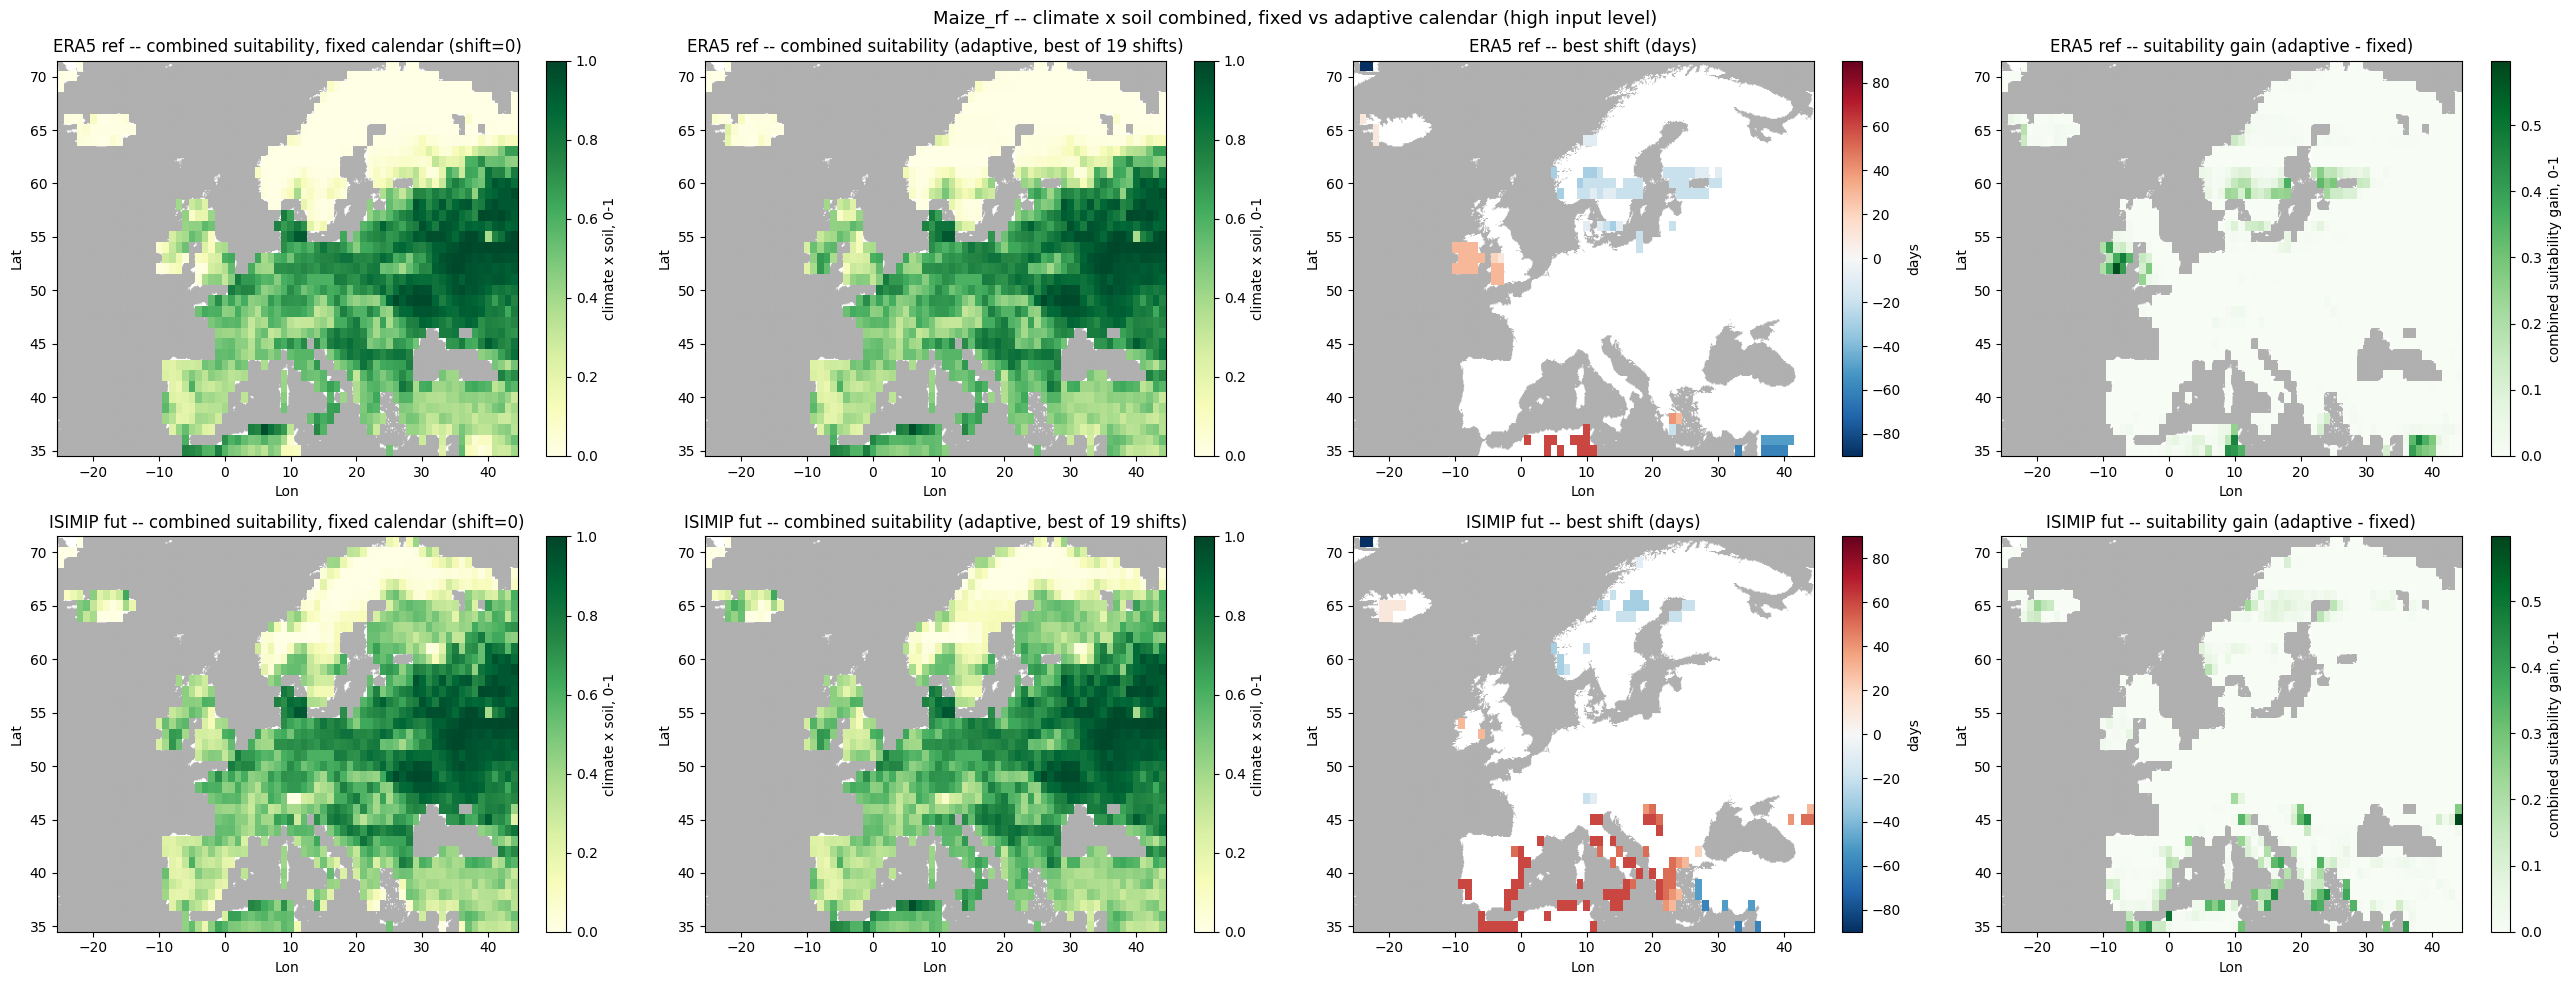

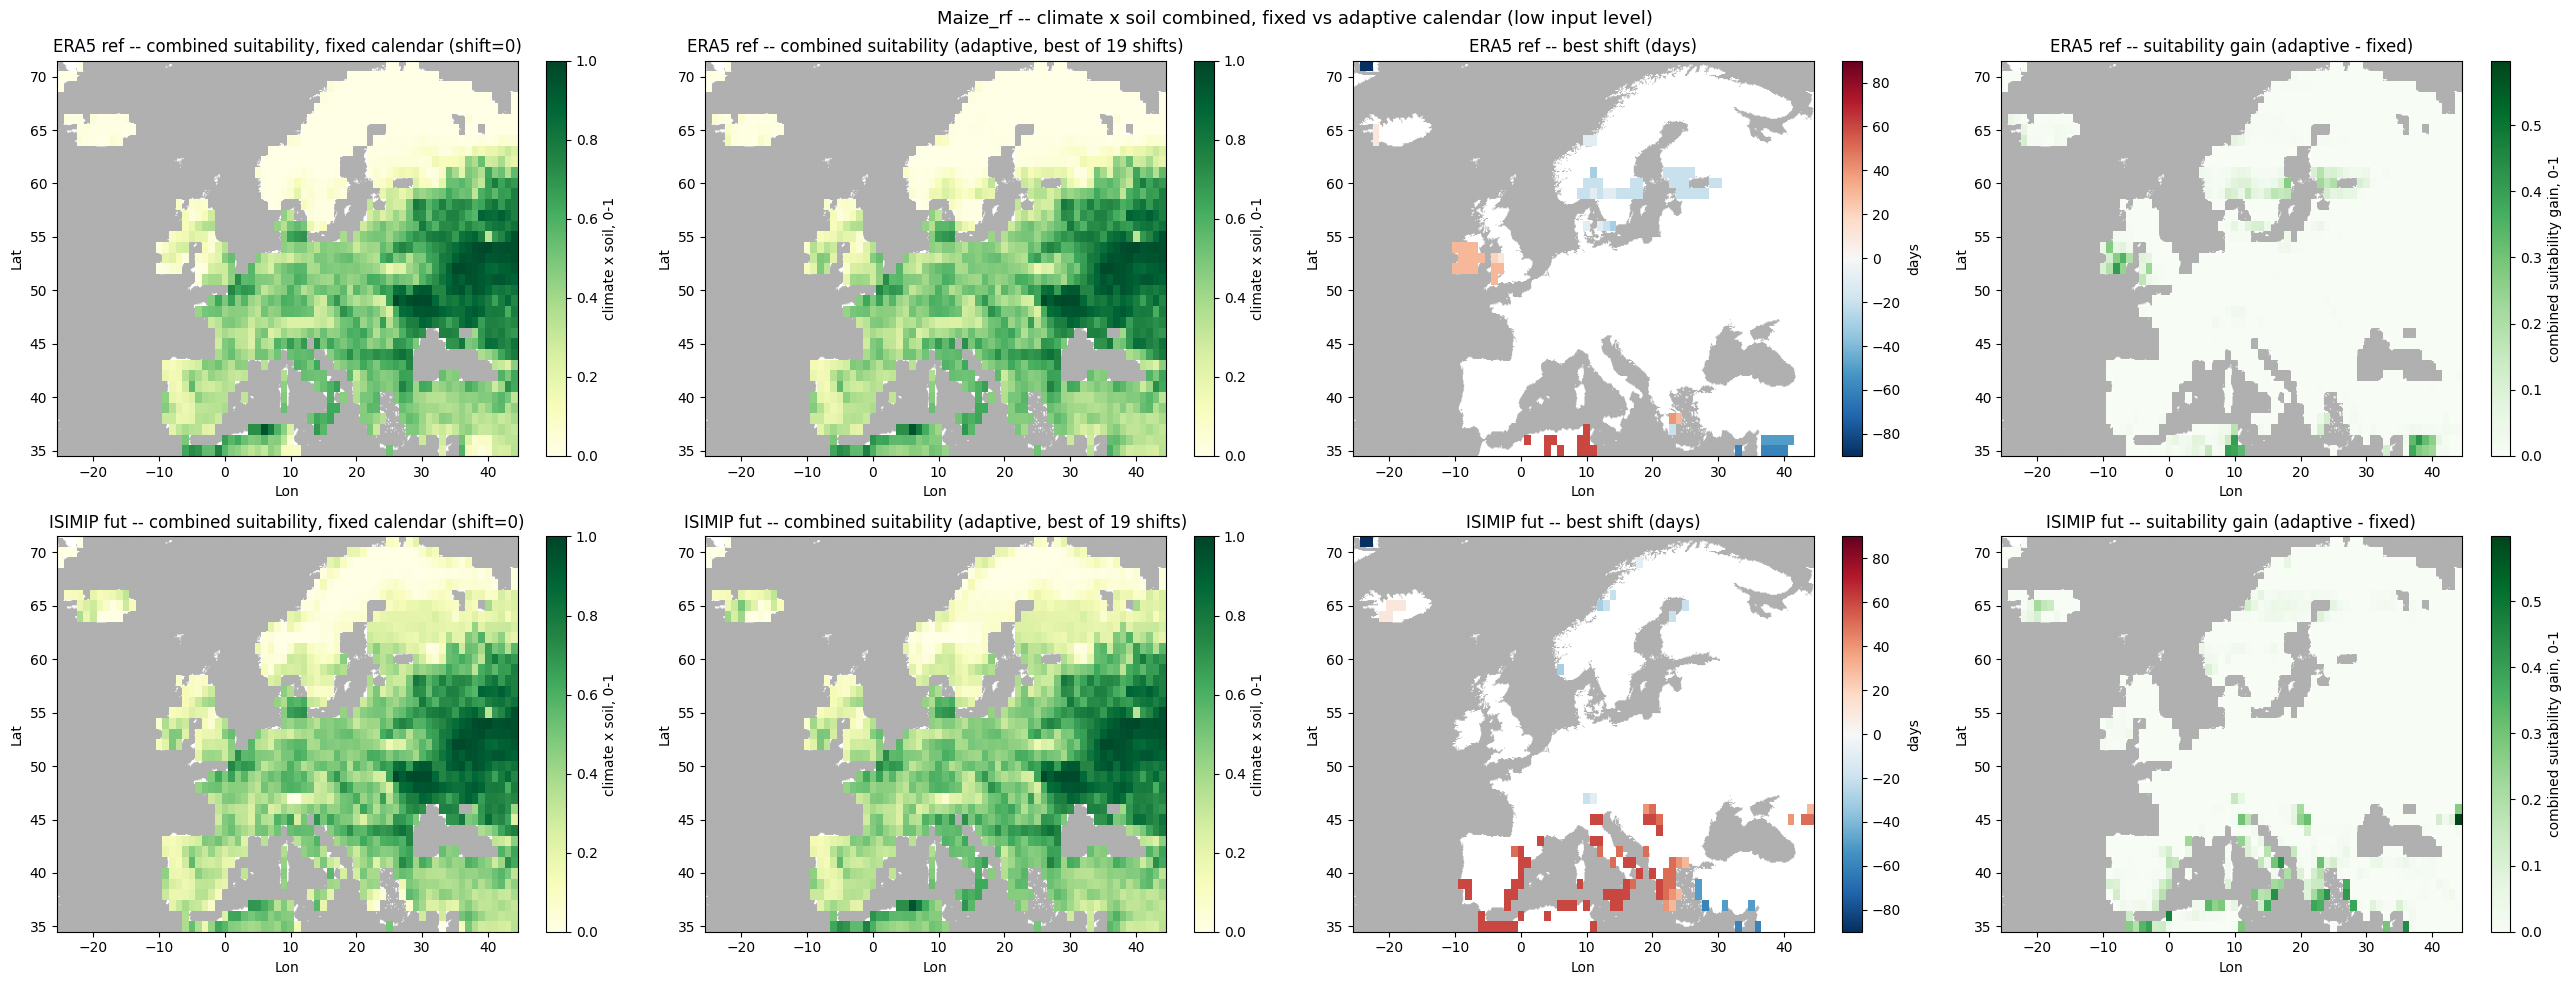

Done.


In [7]:
ext = [lons[0] - 0.5, lons[-1] + 0.5, lats[0] - 0.5, lats[-1] + 0.5]
_shift_vmax = max(abs(min(SHIFTS)), abs(max(SHIFTS)))
# Shared vmax for the 4th (gain) column, across ref+fut+both levels, so the two rows (and
# both input-level figures) stay directly comparable. Gain is >=0 everywhere by
# construction (adaptive is a max over a set that includes shift=0), except for float noise.
_gain_vmax = max(np.nanmax(gain_ref_by_level[lv]) for lv in LEVELS)
_gain_vmax = max(_gain_vmax, max(np.nanmax(gain_fut_by_level[lv]) for lv in LEVELS))

for lv in LEVELS:
    fig, axes = plt.subplots(2, 4, figsize=(26, 10))

    draw_land_ocean_bg(axes[0,0], ext)
    im0 = axes[0,0].imshow(combined_ref[lv][0], origin='lower', aspect='auto', extent=ext,
                            cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[0,0].set_title('ERA5 ref -- combined suitability, fixed calendar (shift=0)')
    plt.colorbar(im0, ax=axes[0,0], label='climate x soil, 0-1')

    draw_land_ocean_bg(axes[0,1], ext)
    im1 = axes[0,1].imshow(adaptive_combined_ref[lv], origin='lower', aspect='auto', extent=ext,
                            cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[0,1].set_title(f'ERA5 ref -- combined suitability (adaptive, best of {len(SHIFTS)} shifts)')
    plt.colorbar(im1, ax=axes[0,1], label='climate x soil, 0-1')

    draw_land_ocean_bg(axes[0,2], ext)
    im2 = axes[0,2].imshow(best_shift_ref[lv], origin='lower', aspect='auto', extent=ext,
                            cmap='RdBu_r', vmin=-_shift_vmax, vmax=_shift_vmax, zorder=1)
    axes[0,2].set_title('ERA5 ref -- best shift (days)')
    plt.colorbar(im2, ax=axes[0,2], label='days')

    draw_land_ocean_bg(axes[0,3], ext)
    im2b = axes[0,3].imshow(gain_ref_by_level[lv], origin='lower', aspect='auto', extent=ext,
                             cmap='Greens', vmin=0, vmax=_gain_vmax, zorder=1)
    axes[0,3].set_title('ERA5 ref -- suitability gain (adaptive - fixed)')
    plt.colorbar(im2b, ax=axes[0,3], label='combined suitability gain, 0-1')

    draw_land_ocean_bg(axes[1,0], ext)
    im3 = axes[1,0].imshow(combined_fut[lv][0], origin='lower', aspect='auto', extent=ext,
                            cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[1,0].set_title('ISIMIP fut -- combined suitability, fixed calendar (shift=0)')
    plt.colorbar(im3, ax=axes[1,0], label='climate x soil, 0-1')

    draw_land_ocean_bg(axes[1,1], ext)
    im4 = axes[1,1].imshow(adaptive_combined_fut[lv], origin='lower', aspect='auto', extent=ext,
                            cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[1,1].set_title(f'ISIMIP fut -- combined suitability (adaptive, best of {len(SHIFTS)} shifts)')
    plt.colorbar(im4, ax=axes[1,1], label='climate x soil, 0-1')

    draw_land_ocean_bg(axes[1,2], ext)
    im5 = axes[1,2].imshow(best_shift_fut[lv], origin='lower', aspect='auto', extent=ext,
                            cmap='RdBu_r', vmin=-_shift_vmax, vmax=_shift_vmax, zorder=1)
    axes[1,2].set_title('ISIMIP fut -- best shift (days)')
    plt.colorbar(im5, ax=axes[1,2], label='days')

    draw_land_ocean_bg(axes[1,3], ext)
    im5b = axes[1,3].imshow(gain_fut_by_level[lv], origin='lower', aspect='auto', extent=ext,
                             cmap='Greens', vmin=0, vmax=_gain_vmax, zorder=1)
    axes[1,3].set_title('ISIMIP fut -- suitability gain (adaptive - fixed)')
    plt.colorbar(im5b, ax=axes[1,3], label='combined suitability gain, 0-1')

    for ax in axes.flat:
        ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
        ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    plt.suptitle(f'{CROP_LABEL} -- climate x soil combined, fixed vs adaptive calendar ({lv} input level)', fontsize=13)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'combined_adaptive_maps_{CROP_LABEL}_{lv}.png', dpi=120)
    plt.show()

print('Done.')

## 6. Summary table

In [8]:
rows = []
for lv in LEVELS:
    for period, arr in [('ERA5_ref', adaptive_combined_ref[lv]), ('ISIMIP_fut', adaptive_combined_fut[lv])]:
        valid = ~np.isnan(arr)
        rows.append({
            'level': lv, 'period': period,
            'combined_mean': float(np.nanmean(arr)),
            'combined_median': float(np.nanmedian(arr)),
            'combined_gt0.5_pct': float(100 * np.nansum(arr[valid] >= 0.5) / valid.sum()),
        })
df_summary = pd.DataFrame(rows)
df_summary.to_csv(OUT_DIR / f'combined_adaptive_summary_{CROP_LABEL}.csv', index=False)
print(df_summary.to_string(index=False))

level     period  combined_mean  combined_median  combined_gt0.5_pct
 high   ERA5_ref       0.469757         0.495047           49.323308
 high ISIMIP_fut       0.520959         0.524778           53.984962
  low   ERA5_ref       0.391848         0.413692           34.887218
  low ISIMIP_fut       0.417944         0.417178           35.338346


## 7. Same, at the soil layer's native 0.25deg resolution

Exact method already established and used in
[5.c)_Apply_ERA5_validation_without_threshold/5.a.bis)_...ipynb](../../5_Suitability_climate_soil_combined_validation/5.c\)_Apply_ERA5_validation_without_threshold/5.a.bis\)_Apply_ERA5_validation_without_threshold.ipynb)
(same no-threshold branch as everywhere else in this folder -- the cell-area-fraction branch
the user pointed at for the reference figure is NOT used, only its figure style was the
pointer) -- no new climate data is invented: the 1deg climate probability is duplicated onto
its 4x4 0.25deg sub-cells (`SUB_PER_DEG = 4`), and multiplied by the soil layer at its true
native 0.25deg resolution (`soil_suitability_<crop>_0.25deg_x0grid<level>.nc`). This is the
"Aletsch glacier" fix from that notebook: soil, and therefore combined suitability, now
varies within a single 1deg climate cell wherever the sub-pixel soil does (e.g. a partially
glaciated cell), which the 1deg-only maps above cannot show.

In [9]:
def load_soil_suitability_fine(crop, level, res_deg=0.25):
    """Same as load_soil_suitability, but the true 0.25deg file (not a 1deg average).
    Verbatim from 5.c)/5.a.bis)."""
    ds = xr.open_dataset(SOIL_DIR / f'soil_suitability_{crop}_{res_deg}deg_x0grid{SOIL_SUFFIX[level]}.nc')
    arr = ds[list(ds.data_vars)[0]].values / 100.0
    flat, flon = ds.lat.values, ds.lon.values
    ds.close()
    return arr, flat, flon

SUB_PER_DEG = 4  # 1deg / 0.25deg
fine_lats = fine_lons = None
soil_idx_fine = {}
for lv in LEVELS:
    arr, flat, flon = load_soil_suitability_fine(CROP_LABEL, lv)
    if fine_lats is None:
        fine_lats, fine_lons = flat, flon
    soil_idx_fine[lv] = arr
    print(f'soil fine ({lv}): mean={np.nanmean(arr):.3f}  shape={arr.shape}')

# Pure duplication of each shift's 1deg climate proba onto its 4x4 sub-cells -- no new
# climate data, just grid alignment for the multiplication.
suit_ref_fine_by_shift = {d: np.repeat(np.repeat(suit_ref_by_shift[d], SUB_PER_DEG, axis=0), SUB_PER_DEG, axis=1) for d in SHIFTS}
suit_fut_fine_by_shift = {d: np.repeat(np.repeat(suit_fut_by_shift[d], SUB_PER_DEG, axis=0), SUB_PER_DEG, axis=1) for d in SHIFTS}

combined_ref_fine, combined_fut_fine = {}, {}
for lv in LEVELS:
    combined_ref_fine[lv] = {d: suit_ref_fine_by_shift[d] * soil_idx_fine[lv] for d in SHIFTS}
    combined_fut_fine[lv] = {d: suit_fut_fine_by_shift[d] * soil_idx_fine[lv] for d in SHIFTS}
print('Fine (0.25deg) combined suitability computed for all shifts, both levels.')

soil fine (high): mean=0.554  shape=(148, 280)


soil fine (low): mean=0.435  shape=(148, 280)
Fine (0.25deg) combined suitability computed for all shifts, both levels.


In [10]:
adaptive_combined_ref_fine, adaptive_combined_fut_fine = {}, {}

# Only the combined-suitability VALUE is needed at fine resolution (the suitability panels,
# columns 1-2). "Best shift" is plotted at its native 1deg resolution instead (reusing
# best_shift_ref[lv]/best_shift_fut[lv] from section 3, see the plotting cell below) -- not
# computed or upsampled here at all, since soil is evaluated at the matching 1deg cell there,
# with no sub-pixel mismatch possible.

# Envelope mask repeated onto the 4x4 sub-cells (block-constant, since the shift validity
# is a climate-only property, see Section 2.5) -- same logic as the 1deg section.
envelope_valid_fine = {d: np.repeat(np.repeat(envelope_valid[d], SUB_PER_DEG, axis=0), SUB_PER_DEG, axis=1) for d in SHIFTS}

for lv in LEVELS:
    stack_ref = np.stack([np.where(envelope_valid_fine[d], combined_ref_fine[lv][d], np.nan) for d in SHIFTS], axis=0)
    stack_fut = np.stack([np.where(envelope_valid_fine[d], combined_fut_fine[lv][d], np.nan) for d in SHIFTS], axis=0)
    adaptive_combined_ref_fine[lv] = np.nanmax(stack_ref, axis=0)
    adaptive_combined_fut_fine[lv] = np.nanmax(stack_fut, axis=0)
    print(f'{lv:4s} (0.25deg): adaptive combined mean -- ref={np.nanmean(adaptive_combined_ref_fine[lv]):.3f}  '
          f'fut={np.nanmean(adaptive_combined_fut_fine[lv]):.3f}')

high (0.25deg): adaptive combined mean -- ref=0.473  fut=0.523
low  (0.25deg): adaptive combined mean -- ref=0.394  fut=0.420


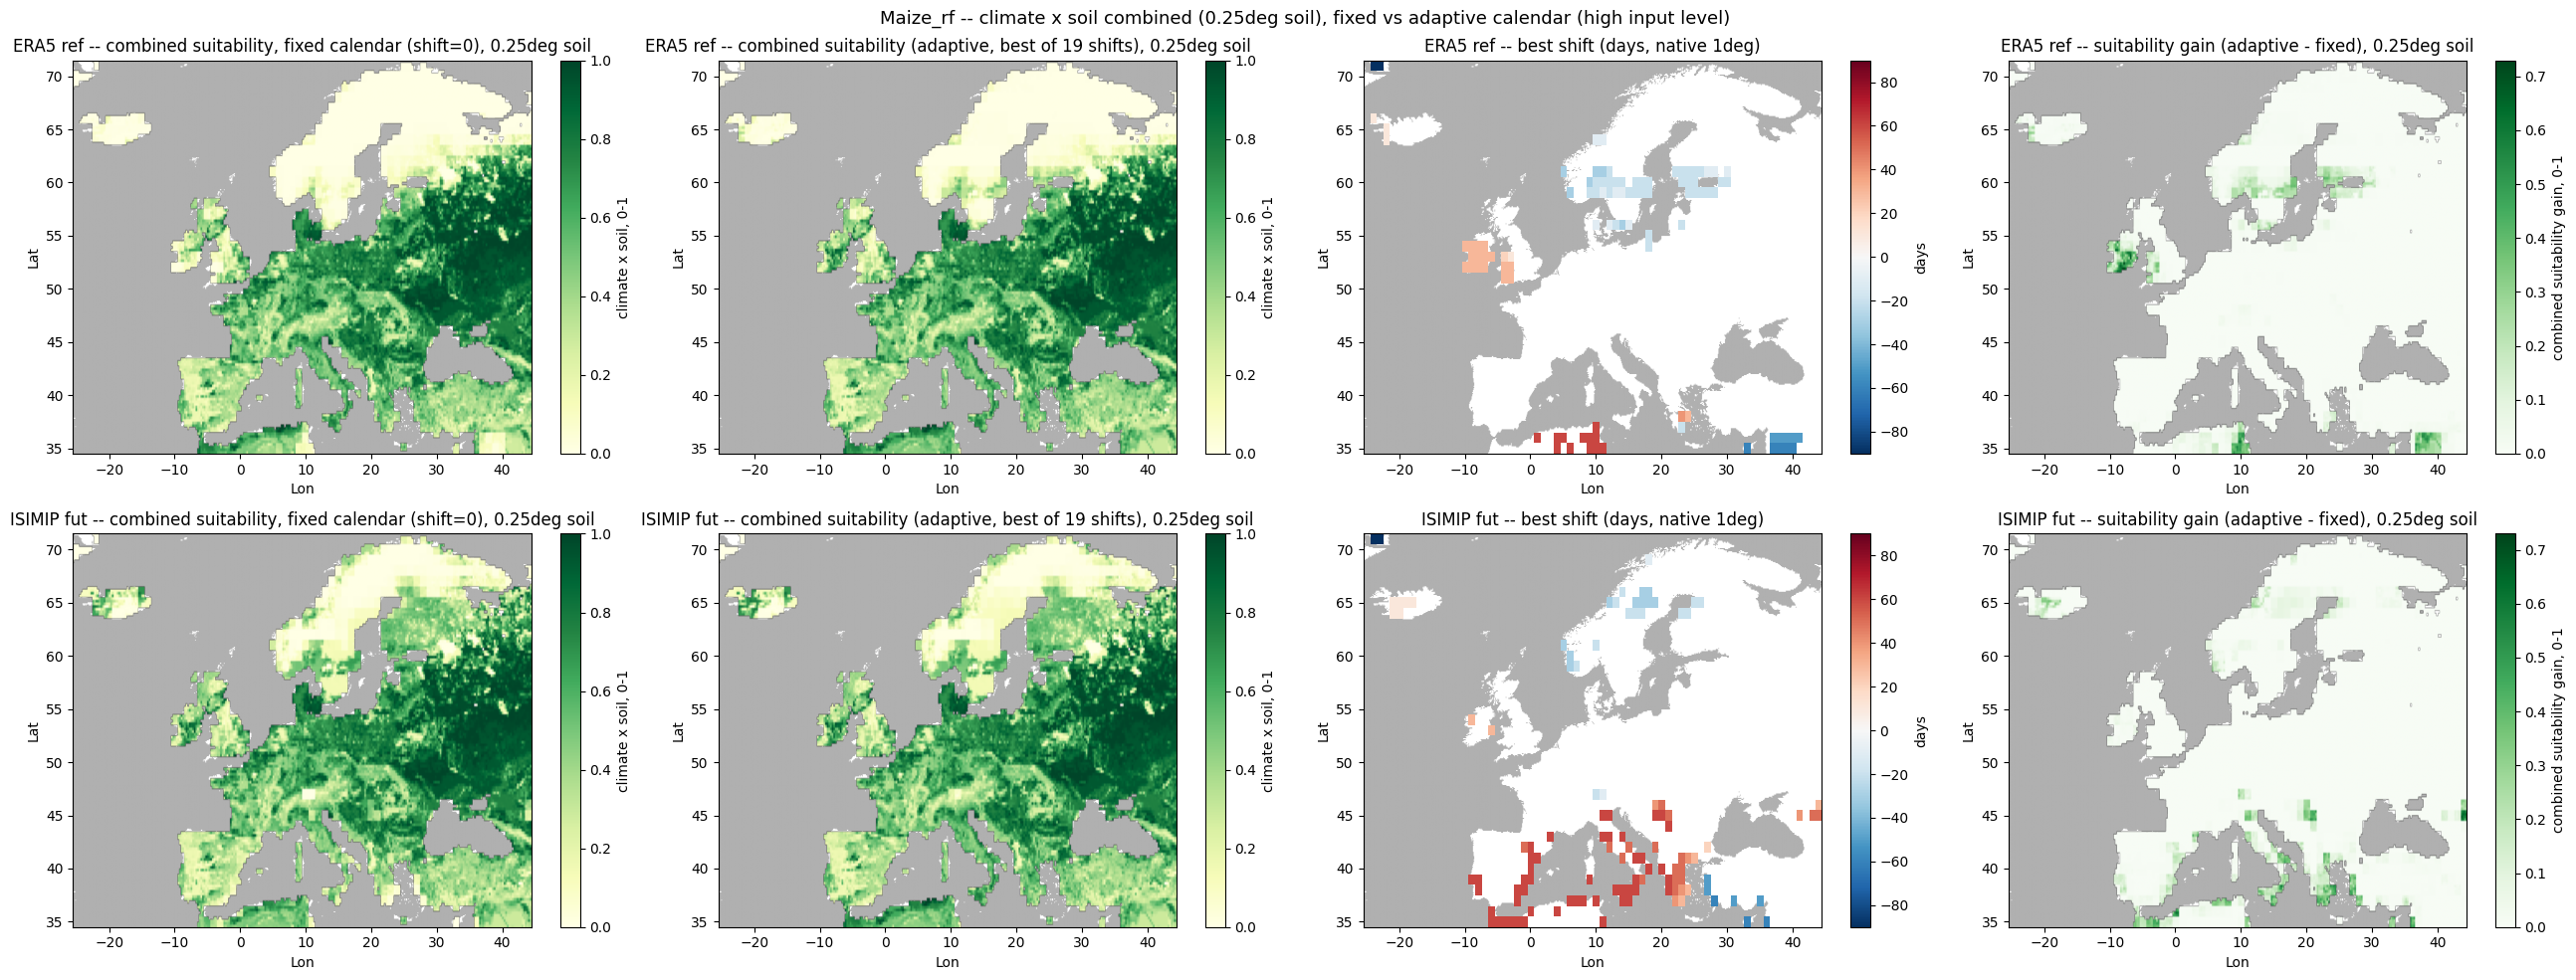

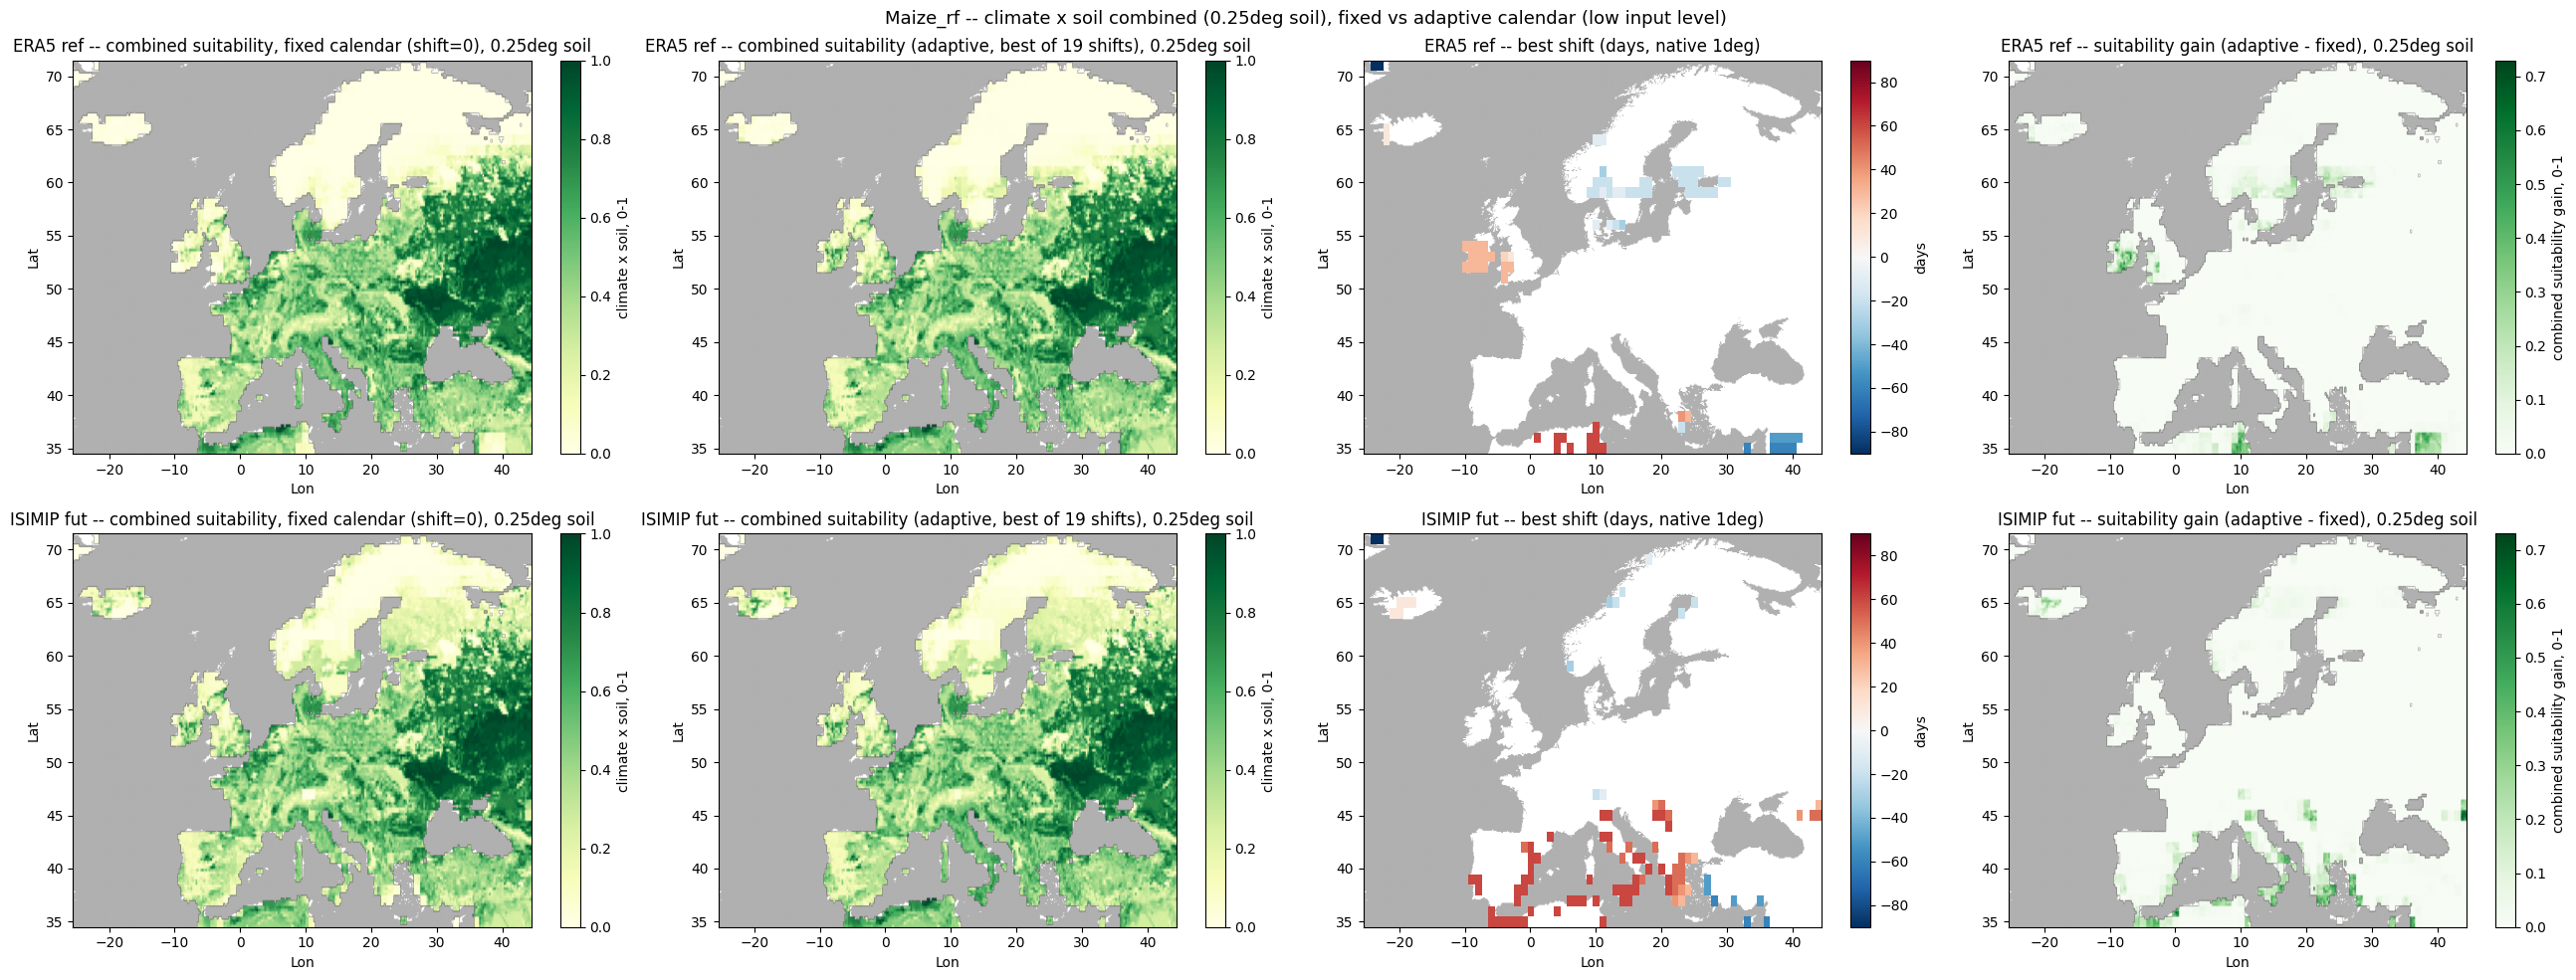

Done (fine resolution).


In [11]:
fine_ext = [fine_lons[0] - 0.125, fine_lons[-1] + 0.125, fine_lats[0] - 0.125, fine_lats[-1] + 0.125]

gain_ref_fine_by_level = {lv: adaptive_combined_ref_fine[lv] - combined_ref_fine[lv][0] for lv in LEVELS}
gain_fut_fine_by_level = {lv: adaptive_combined_fut_fine[lv] - combined_fut_fine[lv][0] for lv in LEVELS}
_gain_vmax_fine = max(np.nanmax(gain_ref_fine_by_level[lv]) for lv in LEVELS)
_gain_vmax_fine = max(_gain_vmax_fine, max(np.nanmax(gain_fut_fine_by_level[lv]) for lv in LEVELS))

for lv in LEVELS:
    fig, axes = plt.subplots(2, 4, figsize=(26, 10))

    draw_land_ocean_bg(axes[0,0], fine_ext)
    im0 = axes[0,0].imshow(combined_ref_fine[lv][0], origin='lower', aspect='auto', extent=fine_ext,
                            cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[0,0].set_title('ERA5 ref -- combined suitability, fixed calendar (shift=0), 0.25deg soil')
    plt.colorbar(im0, ax=axes[0,0], label='climate x soil, 0-1')

    draw_land_ocean_bg(axes[0,1], fine_ext)
    im1 = axes[0,1].imshow(adaptive_combined_ref_fine[lv], origin='lower', aspect='auto', extent=fine_ext,
                            cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[0,1].set_title(f'ERA5 ref -- combined suitability (adaptive, best of {len(SHIFTS)} shifts), 0.25deg soil')
    plt.colorbar(im1, ax=axes[0,1], label='climate x soil, 0-1')

    # Best shift plotted at its NATIVE 1deg resolution (ext, not fine_ext), one colour per
    # 1deg pixel -- not upsampled onto the 0.25deg soil grid. The best shift is a property of
    # the climate cell alone (soil never changes which shift wins, see section 3), so showing
    # it at 0.25deg just inherits soil's own, DIFFERENT land/sea mask: 108 colored 1deg blocks
    # were confirmed to have a mix of valid/NaN soil sub-pixels, producing a "half-coloured
    # pixel" artifact the user caught. best_shift_ref[lv]/best_shift_fut[lv] (1deg, computed
    # in section 3) are reused as-is here instead of best_shift_ref_fine/fut_fine.
    draw_land_ocean_bg(axes[0,2], ext)
    im2 = axes[0,2].imshow(best_shift_ref[lv], origin='lower', aspect='auto', extent=ext,
                            cmap='RdBu_r', vmin=-_shift_vmax, vmax=_shift_vmax, zorder=1)
    axes[0,2].set_title('ERA5 ref -- best shift (days, native 1deg)')
    plt.colorbar(im2, ax=axes[0,2], label='days')

    draw_land_ocean_bg(axes[0,3], fine_ext)
    im2b = axes[0,3].imshow(gain_ref_fine_by_level[lv], origin='lower', aspect='auto', extent=fine_ext,
                             cmap='Greens', vmin=0, vmax=_gain_vmax_fine, zorder=1)
    axes[0,3].set_title('ERA5 ref -- suitability gain (adaptive - fixed), 0.25deg soil')
    plt.colorbar(im2b, ax=axes[0,3], label='combined suitability gain, 0-1')

    draw_land_ocean_bg(axes[1,0], fine_ext)
    im3 = axes[1,0].imshow(combined_fut_fine[lv][0], origin='lower', aspect='auto', extent=fine_ext,
                            cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[1,0].set_title('ISIMIP fut -- combined suitability, fixed calendar (shift=0), 0.25deg soil')
    plt.colorbar(im3, ax=axes[1,0], label='climate x soil, 0-1')

    draw_land_ocean_bg(axes[1,1], fine_ext)
    im4 = axes[1,1].imshow(adaptive_combined_fut_fine[lv], origin='lower', aspect='auto', extent=fine_ext,
                            cmap='YlGn', vmin=0, vmax=1, zorder=1)
    axes[1,1].set_title(f'ISIMIP fut -- combined suitability (adaptive, best of {len(SHIFTS)} shifts), 0.25deg soil')
    plt.colorbar(im4, ax=axes[1,1], label='climate x soil, 0-1')

    draw_land_ocean_bg(axes[1,2], ext)
    im5 = axes[1,2].imshow(best_shift_fut[lv], origin='lower', aspect='auto', extent=ext,
                            cmap='RdBu_r', vmin=-_shift_vmax, vmax=_shift_vmax, zorder=1)
    axes[1,2].set_title('ISIMIP fut -- best shift (days, native 1deg)')
    plt.colorbar(im5, ax=axes[1,2], label='days')

    draw_land_ocean_bg(axes[1,3], fine_ext)
    im5b = axes[1,3].imshow(gain_fut_fine_by_level[lv], origin='lower', aspect='auto', extent=fine_ext,
                             cmap='Greens', vmin=0, vmax=_gain_vmax_fine, zorder=1)
    axes[1,3].set_title('ISIMIP fut -- suitability gain (adaptive - fixed), 0.25deg soil')
    plt.colorbar(im5b, ax=axes[1,3], label='combined suitability gain, 0-1')

    for ax in [axes[0,0], axes[0,1], axes[0,3], axes[1,0], axes[1,1], axes[1,3]]:
        ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
        ax.set_xlim(fine_ext[0], fine_ext[1]); ax.set_ylim(fine_ext[2], fine_ext[3])
    for ax in [axes[0,2], axes[1,2]]:
        ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
        ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3])
    plt.suptitle(f'{CROP_LABEL} -- climate x soil combined (0.25deg soil), fixed vs adaptive calendar ({lv} input level)', fontsize=13)
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'combined_adaptive_maps_fine_{CROP_LABEL}_{lv}.png', dpi=120)
    plt.show()

print('Done (fine resolution).')

## 8. Known limitation -- why "best shift" keeps pushing to the edge of the tested range (+-90d)

Extending the tested range from +-60 to +-90 days did not stabilise the "best shift" choice
-- the share of real-gain pixels (combined gain >= 0.05) sitting exactly at the edge of the
tested range actually *increased* (ERA5 ref: 72% at +-60 -> 84% at +-90; ISIMIP fut: 54% ->
65%), overwhelmingly at the **positive** edge (+90), concentrated in cold, high-latitude
pixels (Scandinavia, NE Europe/Russia -- see the "best shift" maps in Section 5). Extending
further (+-120d, +-150d...) would very likely keep chasing the same edge rather than
converge on an interior optimum, so the range is **not extended past +-90d**; this is
recorded as a limitation of the method, not fixed.

**This is not a duration bug.** The shift cell (`7.a)`/`7.b)`) moves `sowing_doy` AND
`maturity_doy` by the identical `CALENDAR_SHIFT_DAYS`, so `maturity - sowing` (the growing
season length) is exactly preserved at every tested shift -- the whole season (sowing ->
anthesis -> maturity) translates as a single rigid block, it is never just the sowing date
moving while the cycle length drifts. An earlier explanation offered to the user claiming
the cycle length broke down was incorrect and has been corrected here.

**The real mechanism**: since the season's length is fixed, sliding the whole block later in
the year for a cold, high-latitude pixel can genuinely capture a warmer portion of the
year -- that part of the signal is real, not an artifact. What the model has no way to
penalise is the point past which a later harvest would, in reality, run into the autumn
frost / shortening photoperiod and fail before reaching maturity: the SVM only ever sees
*averaged* BIO variables (BIO12 = Tmin of the coldest month in the window gives a soft
signal, but not a hard frost-kill threshold with a phenological consequence), and the
MIRCA2000 training data never contains a real-world window that ends in frost (because no
farmer actually plants that way), so the model has no grounded examples from which to learn
that specific failure mode. A later, large positive shift keeps looking better to the model
because it keeps finding warmer average conditions, with nothing in the training signal to
tell it when the harvest date has become agronomically unsafe.

**Consequence (as first found, before the fix below)**: the "best shift"/"adaptive
suitability" results for cold, high-latitude pixels (where the edge-hugging concentrated)
read as an upper bound inflated by this missing constraint, not a literally achievable gain
-- unlike the more moderate, interior-optimum shifts found for most of central/southern
Europe, unaffected by this issue.

**Fixed in Section 2.5, applied retroactively above**: rather than hand-coding a
physiological guardrail (which would need to be reinvented per crop -- a frost threshold is
the wrong direction entirely for Wheat-winter's vernalisation requirement, see the
discussion with the user that led to this), every shift tested above is now additionally
masked per pixel to an empirical envelope of real MIRCA2000 sowing dates observed among
*climatically comparable* (adaptive latitude-band) pixels, not just "observed somewhere in
Europe" (revised again after the user pointed out that a future global run would make a
single whole-domain bound meaningless -- see Section 2.5's own markdown for why the fix had
to be latitude-based, not area-based). This stays a crop-agnostic *method* (only the numeric
bound is crop- and latitude-specific, read directly off that crop's own real calendar data)
that keeps every tested input inside the region the SVM actually learned from, instead of
trying to teach it why a calendar is unrealistic.